# Power to detect enhancer–gene effects in cis

How much does sampling more cells per enhancer improve detection at a fixed effect size? Start with the fitted K562 screen from the [Gasperini analysis](gasperini.ipynb). Simulate one affected cis gene per active enhancer, analyze each draw with PerTurbo, and compare the fraction of planted links recovered. At the end we zoom in on the **PPP2R5A** neighborhood.

Run the analysis notebook first, then start here in the same tutorial directory. The default uses three draws per condition on CPU. Set `PERTURBO_TUTORIAL_QUICK=1` before launching Jupyter to run one draw per condition as a workflow check. The full benchmark uses many more elements, higher multiplicity, the full gene axis and more coverage settings.

In [1]:
from pathlib import Path
from itertools import product
import json
import os
import shlex
import subprocess
import sys
import tempfile
import time

import h5py
import matplotlib.pyplot as plt
import mudata as md
import numpy as np
import pandas as pd
from anndata.io import read_elem
from scipy.stats import false_discovery_control

from gasperini_power_design import choose_pairs, write_draw

fitted = Path("runs/gasperini/fitted.h5mu")
cis_file = Path("../../examples/manuscript/gasperini-cis-candidates.parquet")
if not fitted.exists():
    raise FileNotFoundError("Run gasperini.ipynb first to generate runs/gasperini/fitted.h5mu.")
assays = md.read_h5mu(fitted)
declared = pd.read_parquet(cis_file)
work = Path(tempfile.mkdtemp(prefix="gasperini-power-", dir="runs"))

## Fix the test family and generating effects

Select up to 32 measured enhancers with at least two candidate genes in the teaching subset, including six near PPP2R5A. Reserve a quarter of the elements as complete nulls. For each remaining element, choose one target at random among its candidate genes, without using observed effects or p-values. All other candidate pairs have zero simulated effect.

Each element has two guides. Draw their efficiencies once, with replacement, from the 734 fitted efficiencies of significant Gasperini TSS–gene on-target pairs used in Figure 2. These estimates represent that selected guide pool. The grid varies the **parent** lnFC; a guide with efficiency η imposes η × lnFC. Cells carrying both guides receive the sum of their contributions.

In [2]:
SEED = 37
coverages = [40, 160]             # expected unique cells carrying either guide per element
parent_lnfcs = [-0.5, -1.0]
n_draws = 1 if os.environ.get("PERTURBO_TUTORIAL_QUICK") == "1" else 3
q_cutoff = 0.10

elements, pairs, locus = choose_pairs(assays, declared, seed=SEED)
eta_pool = np.load("inputs/gasperini_tss_efficiency.npy")
eta = np.random.default_rng(SEED + 1).choice(eta_pool, size=(len(elements), 2), replace=True)
cis = work / "cis.parquet"
pairs[["element", "gene"]].to_parquet(cis, index=False)
pairs.to_csv(work / "truth.csv", index=False)
pd.DataFrame(eta, index=elements, columns=["guide_1", "guide_2"]).to_csv(work / "guide_truth.csv")
print(f"{len(elements)} elements, {pairs.gene.nunique()} genes, {len(pairs)} cis tests, "
      f"{pairs.planted.sum()} planted links; {len(locus)} focal elements")

32 elements, 98 genes, 187 cis tests, 24 planted links; 6 focal elements


## Simulate and test the grid

For each draw, sample donor cells from the fitted screen, carrying their fitted offsets, covariates and native batch labels together. Draw guide assignments with the Figure 2 covariate slopes and an intercept chosen so that the expected number of cells with **either** guide equals the requested coverage. Here each cell carries about four distinct elements on average. Donors and assignments are matched across effect sizes within a draw; RNA counts are newly sampled from PerTurbo’s NumPyro model using the fitted baseline means, dispersions and covariate coefficients.

Test each simulated screen through the CLI. We use the generating offsets: depth computed from this restricted panel would change when its genes respond. The CLI calculates association scores over the simulated element and gene axes. Passing the candidate table to `--cis-pairs` defines a **single cis BH family** for scoring. The grid only needs association tests, so it can skip fitting the stage-two effects on the simulated data.

In [3]:
common = [
    sys.executable, "-m", "perturbo.cli", "--device", "cpu",
    "--modality-key", "gene", "--perturbation-modality-key", "guide",
    "--perturbation-element-varm-key", "mapping",
    "--perturbation-element-names-uns-key", "elements",
    "--batch-covariate", "prep_batch", "--continuous-covariates", "total_umis", "percent_mito",
    "--size-factor-mode", "observed", "--size-factor-key", "log_sf",
    "--likelihood", "negbin", "--crt-only", "--crt-pool", "all-cells",
    "--crt-polish-baseline", "--no-crt-allow-unconverged-baseline",
    "--num-steps", "500", "--step-size", "0.01",
    "--crt-gene-chunk-size", "32", "--crt-max-gather-gib", "1",
    "--cis-pairs", str(cis), "--no-progress-bar",
]
print(shlex.join(common))

python -m perturbo.cli --device cpu --modality-key gene --perturbation-modality-key guide --perturbation-element-varm-key mapping --perturbation-element-names-uns-key elements --batch-covariate prep_batch --continuous-covariates total_umis percent_mito --size-factor-mode observed --size-factor-key log_sf --likelihood negbin --crt-only --crt-pool all-cells --crt-polish-baseline --no-crt-allow-unconverged-baseline --num-steps 500 --step-size 0.01 --crt-gene-chunk-size 32 --crt-max-gather-gib 1 --cis-pairs runs/gasperini-power-x4p5k9t5/cis.parquet --no-progress-bar


In [4]:
results = []
start = time.monotonic()
for coverage, scenario, replicate in product(coverages, range(len(parent_lnfcs)), range(n_draws)):
    lnfc = parent_lnfcs[scenario]
    folder = work / f"cpe{coverage}_lfc{lnfc:g}_rep{replicate}"
    folder.mkdir()
    source = folder / "sim.h5mu"
    realized = write_draw(assays, elements, pairs, eta, source, coverage=coverage,
                          parent_lnfc=lnfc, replicate=replicate, scenario=scenario, seed=SEED)
    command = [*common, "--input", str(source), "--out-dir", str(folder / "fit")]
    (folder / "command.json").write_text(json.dumps(command))
    with (folder / "cli.log").open("w") as log:
        job = subprocess.run(command, stdout=log, stderr=subprocess.STDOUT)
    if job.returncode:
        raise RuntimeError(f"{folder}: " + (folder / "cli.log").read_text()[-3000:])
    with h5py.File(folder / "fit" / "fitted.h5mu") as h:
        effects = read_elem(h["uns/_perturbo/effects"])
    scored = pairs.merge(effects[["element", "gene", "p_value", "q_cis"]],
                         on=["element", "gene"], validate="one_to_one")
    assert len(scored) == len(pairs)
    finite = scored.p_value.notna()
    assert finite.any() and scored.q_cis.notna().equals(finite)
    np.testing.assert_allclose(scored.loc[finite, "q_cis"],
                               false_discovery_control(scored.loc[finite, "p_value"]))
    results.append(scored.assign(coverage=coverage, lnfc=lnfc, replicate=replicate,
                                 realized_cells=realized, called=scored.q_cis.lt(q_cutoff)))
results = pd.concat(results, ignore_index=True)
results.to_parquet(work / "recovery.parquet", index=False)
print(f"{len(results) // len(pairs)} fits in {(time.monotonic()-start)/60:.1f} min. Outputs: {work}")

12 fits in 3.4 min. Outputs: runs/gasperini-power-x4p5k9t5


## How does recovery change with coverage?

Power is the fraction of planted pairs called at cis q < 0.10. Every planted pair stays in the denominator, including any pair with an unsupported test. Faint points are independent draws and the lines connect their means. The table includes the number of calls among true nulls and unsupported tests.

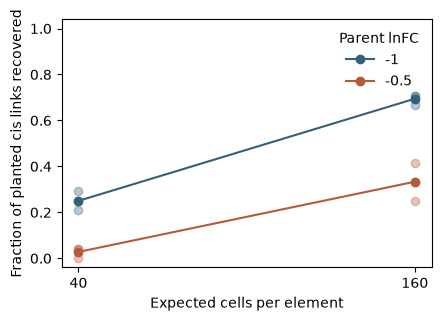

realized_cells  true_calls  false_calls  unsupported
coverage lnfc                                                      
40       -1.0           40.31        6.00         1.00         0.67
         -0.5           40.31        0.67         0.00         0.00
160      -1.0          160.75       16.67         1.00         0.00
         -0.5          160.75        8.00         1.33         0.00

In [5]:
results["true_call"] = results.planted & results.called
results["false_call"] = ~results.planted & results.called
results["unsupported"] = results.q_cis.isna()
by_draw = results.groupby(["coverage", "lnfc", "replicate"], as_index=False).agg(
    planted=("planted", "sum"), true_calls=("true_call", "sum"), false_calls=("false_call", "sum"),
    unsupported=("unsupported", "sum"), realized_cells=("realized_cells", "first"))
by_draw["power"] = by_draw.true_calls / by_draw.planted
fig, ax = plt.subplots(figsize=(4.3, 3), layout="constrained")
for (lnfc, group), color in zip(by_draw.groupby("lnfc"), ["#34617a", "#b55b39"]):
    line = group.groupby("coverage").power.mean()
    ax.scatter(group.coverage, group.power, color=color, alpha=0.35)
    ax.plot(line.index, line, "o-", color=color, label=f"{lnfc:g}")
ax.set(xlabel="Expected cells per element", ylabel="Fraction of planted cis links recovered",
       ylim=(-0.04, 1.04), xticks=coverages)
ax.legend(title="Parent lnFC", frameon=False)
plt.show()
by_draw.groupby(["coverage", "lnfc"])[["realized_cells", "true_calls", "false_calls", "unsupported"]].mean().round(2)

## Which planted links are detectable around PPP2R5A?

Each row is a real candidate enhancer–gene pair assigned a synthetic effect in this experiment. The numbers are independent draws in which the pair passed cis BH correction. With few draws, zero recoveries are compatible with a range of underlying powers. Increase `n_draws` before using per-link estimates to choose a design.

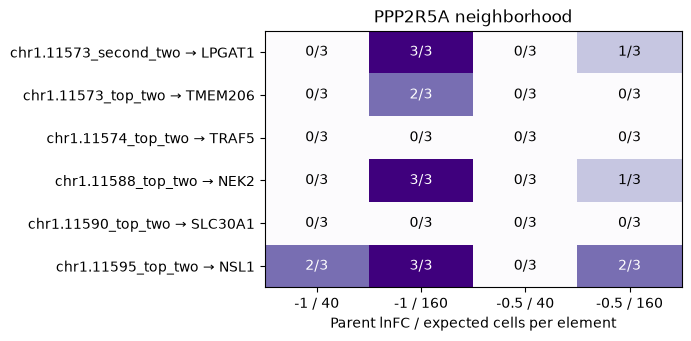

In [6]:
target_symbols = assays.mod["gene"].var["symbol"]
focal = results.loc[results.element.isin(locus) & results.planted].copy()
focal["link"] = focal.element + " → " + focal.gene.map(target_symbols).astype(str)
matrix = focal.pivot_table(index="link", columns=["lnfc", "coverage"],
                           values="called", aggfunc="sum").sort_index(axis=1)
fig, ax = plt.subplots(figsize=(6.8, 3.3), layout="constrained")
image = ax.imshow(matrix / n_draws, vmin=0, vmax=1, aspect="auto", cmap="Purples")
for row, col in np.ndindex(matrix.shape):
    hits = int(matrix.iloc[row, col])
    ax.text(col, row, f"{hits}/{n_draws}", ha="center", va="center",
            color="white" if hits / n_draws > 0.55 else "black")
ax.set(yticks=np.arange(len(matrix)), yticklabels=matrix.index,
       xticks=np.arange(len(matrix.columns)),
       xticklabels=[f"{lnfc:g} / {cpe}" for lnfc, cpe in matrix.columns],
       xlabel="Parent lnFC / expected cells per element", title="PPP2R5A neighborhood")
plt.show()